# Deep Learning with TensorFlow & Keras (deeplizard)

This notebook walks through the main steps covered in the **deeplizard** TensorFlow/Keras playlist, building a complete workflow from data loading to a fine‑tuned MobileNet model. All code runs on CPU/GPU (if available) and uses only the built‑in `tf.keras.datasets` and TensorFlow Hub for the pretrained model.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import itertools

# Set random seed for reproducibility
tf.random.set_seed(42)
np.random.seed(42)


##  Load & Explore Data (MNIST)

We use the classic **MNIST** handwritten‑digit dataset – 60 k training images and 10 k test images.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


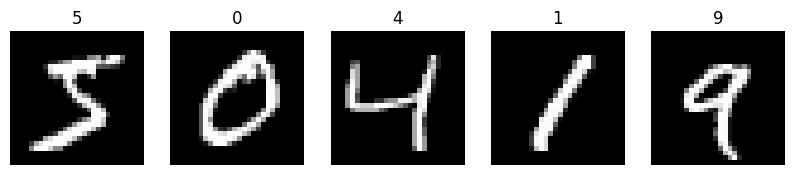

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Visual sanity check – first 5 samples
plt.figure(figsize=(10,2))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(y_train[i])
    plt.axis('off')
plt.show()


##  Data Pre‑processing

* Normalize pixel values to **[0, 1]**.
* Flatten images for a dense network.
* Convert labels to one‑hot vectors when needed.

In [3]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# For dense networks we flatten 28×28 → 784
x_train_flat = x_train.reshape(-1, 28*28)
x_test_flat = x_test.reshape(-1, 28*28)


##  Build a Simple ANN

A classic 2‑layer fully‑connected network.

In [4]:
def build_ann():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

ann = build_ann()
ann.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

##  Train the ANN (with validation split)

In [5]:
history_ann = ann.fit(x_train_flat, y_train,
                    epochs=10,
                    batch_size=128,
                    validation_split=0.1,
                    verbose=2)


Epoch 1/10
422/422 - 23s - 54ms/step - accuracy: 0.9065 - loss: 0.3156 - val_accuracy: 0.9658 - val_loss: 0.1110
Epoch 2/10
422/422 - 1s - 2ms/step - accuracy: 0.9603 - loss: 0.1308 - val_accuracy: 0.9732 - val_loss: 0.0846
Epoch 3/10
422/422 - 1s - 2ms/step - accuracy: 0.9718 - loss: 0.0919 - val_accuracy: 0.9768 - val_loss: 0.0786
Epoch 4/10
422/422 - 1s - 2ms/step - accuracy: 0.9779 - loss: 0.0702 - val_accuracy: 0.9792 - val_loss: 0.0739
Epoch 5/10
422/422 - 1s - 2ms/step - accuracy: 0.9819 - loss: 0.0593 - val_accuracy: 0.9785 - val_loss: 0.0766
Epoch 6/10
422/422 - 1s - 2ms/step - accuracy: 0.9843 - loss: 0.0485 - val_accuracy: 0.9785 - val_loss: 0.0729
Epoch 7/10
422/422 - 1s - 2ms/step - accuracy: 0.9861 - loss: 0.0435 - val_accuracy: 0.9790 - val_loss: 0.0741
Epoch 8/10
422/422 - 1s - 2ms/step - accuracy: 0.9878 - loss: 0.0372 - val_accuracy: 0.9817 - val_loss: 0.0683
Epoch 9/10
422/422 - 1s - 2ms/step - accuracy: 0.9892 - loss: 0.0331 - val_accuracy: 0.9788 - val_loss: 0.0734

##  Evaluate & Confusion Matrix

We compute accuracy on the test set and visualise a confusion matrix.

Test accuracy (ANN): 0.9747
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


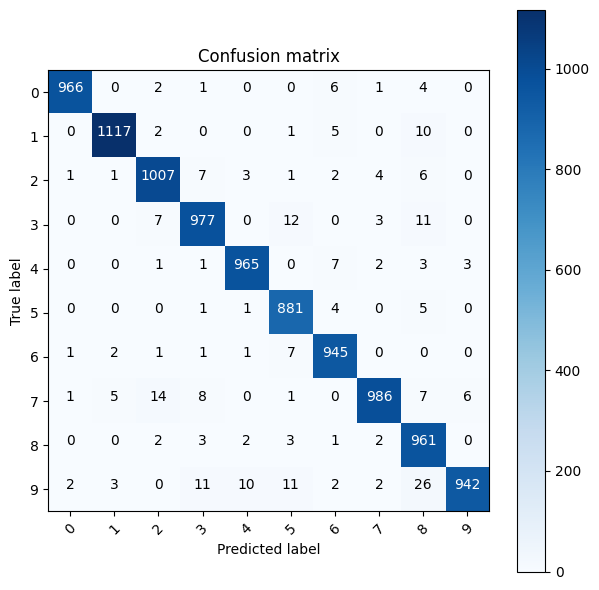

In [6]:
test_loss, test_acc = ann.evaluate(x_test_flat, y_test, verbose=0)
print(f'Test accuracy (ANN): {test_acc:.4f}')

y_pred = np.argmax(ann.predict(x_test_flat), axis=1)
cm = confusion_matrix(y_test, y_pred)

def plot_confusion_matrix(cm, classes, normalize=False, title='Confusion matrix'):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    plt.figure(figsize=(6,6))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)
    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment='center',
                 color='white' if cm[i, j] > thresh else 'black')
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

plot_confusion_matrix(cm, classes=[str(i) for i in range(10)])


##  Save & Load Model

We serialize the ANN to an **`.h5`** file and reload it to demonstrate reproducibility.

In [7]:
ann.save('ann_mnist.h5')
# Load back
loaded_ann = tf.keras.models.load_model('ann_mnist.h5')
loaded_ann.evaluate(x_test_flat, y_test, verbose=0)


[0.08283853530883789, 0.9746999740600586]

## Build a Convolutional Neural Network (CNN)

CNNs are better suited for image data because they exploit spatial locality.

In [8]:
# Reshape for CNN: (batch, 28, 28, 1)
x_train_cnn = x_train[..., np.newaxis]
x_test_cnn = x_test[..., np.newaxis]

def build_cnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Conv2D(32, 3, activation='relu', input_shape=(28,28,1)),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64, 3, activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

cnn = build_cnn()
cnn.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

### Train CNN

In [9]:
history_cnn = cnn.fit(x_train_cnn, y_train,
                    epochs=10,
                    batch_size=128,
                    validation_split=0.1,
                    verbose=2)


Epoch 1/10
422/422 - 16s - 37ms/step - accuracy: 0.9373 - loss: 0.2129 - val_accuracy: 0.9813 - val_loss: 0.0648
Epoch 2/10
422/422 - 1s - 3ms/step - accuracy: 0.9819 - loss: 0.0594 - val_accuracy: 0.9887 - val_loss: 0.0415
Epoch 3/10
422/422 - 1s - 3ms/step - accuracy: 0.9875 - loss: 0.0409 - val_accuracy: 0.9898 - val_loss: 0.0393
Epoch 4/10
422/422 - 1s - 3ms/step - accuracy: 0.9902 - loss: 0.0304 - val_accuracy: 0.9897 - val_loss: 0.0401
Epoch 5/10
422/422 - 1s - 3ms/step - accuracy: 0.9926 - loss: 0.0232 - val_accuracy: 0.9902 - val_loss: 0.0399
Epoch 6/10
422/422 - 1s - 3ms/step - accuracy: 0.9944 - loss: 0.0184 - val_accuracy: 0.9900 - val_loss: 0.0379
Epoch 7/10
422/422 - 1s - 3ms/step - accuracy: 0.9952 - loss: 0.0156 - val_accuracy: 0.9908 - val_loss: 0.0383
Epoch 8/10
422/422 - 1s - 3ms/step - accuracy: 0.9964 - loss: 0.0121 - val_accuracy: 0.9907 - val_loss: 0.0433
Epoch 9/10
422/422 - 1s - 3ms/step - accuracy: 0.9961 - loss: 0.0111 - val_accuracy: 0.9895 - val_loss: 0.0462

##  Data Augmentation (ImageDataGenerator)

We use `tf.keras.preprocessing.image.ImageDataGenerator` to apply random rotations, shifts, and flips on‑the‑fly.

In [10]:
datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=False)

# Fit only required for certain preprocessing – here we just call flow
train_generator = datagen.flow(x_train_cnn, y_train, batch_size=128)

cnn_aug = build_cnn()
cnn_aug.fit(train_generator,
            epochs=10,
            validation_data=(x_test_cnn, y_test),
            verbose=2)


Epoch 1/10
469/469 - 28s - 61ms/step - accuracy: 0.8765 - loss: 0.3973 - val_accuracy: 0.9752 - val_loss: 0.0793
Epoch 2/10
469/469 - 16s - 34ms/step - accuracy: 0.9598 - loss: 0.1313 - val_accuracy: 0.9870 - val_loss: 0.0462
Epoch 3/10
469/469 - 16s - 34ms/step - accuracy: 0.9718 - loss: 0.0930 - val_accuracy: 0.9907 - val_loss: 0.0324
Epoch 4/10
469/469 - 16s - 34ms/step - accuracy: 0.9775 - loss: 0.0721 - val_accuracy: 0.9881 - val_loss: 0.0360
Epoch 5/10
469/469 - 16s - 34ms/step - accuracy: 0.9811 - loss: 0.0616 - val_accuracy: 0.9903 - val_loss: 0.0289
Epoch 6/10
469/469 - 16s - 35ms/step - accuracy: 0.9825 - loss: 0.0581 - val_accuracy: 0.9927 - val_loss: 0.0245
Epoch 7/10
469/469 - 16s - 34ms/step - accuracy: 0.9833 - loss: 0.0520 - val_accuracy: 0.9894 - val_loss: 0.0351
Epoch 8/10
469/469 - 16s - 35ms/step - accuracy: 0.9849 - loss: 0.0477 - val_accuracy: 0.9916 - val_loss: 0.0267
Epoch 9/10
469/469 - 16s - 35ms/step - accuracy: 0.9861 - loss: 0.0439 - val_accuracy: 0.9927 - 

##  Fine‑tune a Pre‑trained MobileNet on a Custom Subset

We switch to a more realistic image dataset – **Fashion MNIST** – and fine‑tune MobileNet (pre‑trained on ImageNet).
*Note*: MobileNet expects 3‑channel 224×224 images, so we resize and repeat channels.

In [12]:
import tensorflow as tf

# Load Fashion MNIST (10 classes)
(fx_train, fy_train), (fx_test, fy_test) = tf.keras.datasets.fashion_mnist.load_data()

# Generator helper for resizing on-the-fly to avoid OOM
def preprocess_image(image, label):
    # Add channel dimension, resize, and convert to RGB
    image = tf.expand_dims(image, -1)
    image = tf.image.resize_with_pad(image, 224, 224)
    image = tf.image.grayscale_to_rgb(image)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# Create tf.data.Dataset pipelines
batch_size = 64

train_dataset = tf.data.Dataset.from_tensor_slices((fx_train, fy_train))
train_dataset = train_dataset.shuffle(buffer_size=1024).map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((fx_test, fy_test))
test_dataset = test_dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size).prefetch(tf.data.AUTOTUNE)

# Load MobileNetV2 without top classifier
base_model = tf.keras.applications.MobileNetV2(input_shape=(224,224,3),
                                               include_top=False,
                                               weights='imagenet')
base_model.trainable = False  # freeze backbone

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# Train using tf.data.Dataset instead of huge in-memory numpy arrays
model.fit(train_dataset, epochs=5, validation_data=test_dataset, verbose=2)

# Unfreeze last 20% of the backbone for fine‑tuning
base_model.trainable = True
fine_tune_at = int(len(base_model.layers) * 0.8)
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.fit(train_dataset, epochs=5, validation_data=test_dataset, verbose=2)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/5
938/938 - 62s - 66ms/step - accuracy: 0.8521 - loss: 0.4101 - val_accuracy: 0.8853 - val_loss: 0.3136
Epoch 2/5
938/938 - 17s - 18ms/step - accuracy: 0.8910 - loss: 0.2982 - val_accuracy: 0.8944 - val_loss: 0.2874
Epoch 3/5
938/938 - 17s - 18ms/step - accuracy: 0.9008 - loss: 0.2694 - val_accuracy: 0.8961 - val_loss: 0.2809
Epoch 4/5
938/938 - 17s - 18ms/step - accuracy: 0.9061 - loss: 0.2490 - val_accuracy: 0.9016 - val_loss: 0.2682
Epoch 5/5
938/938 - 17s - 18ms/step - accuracy: 0.9124 - loss: 0.2327 - val_accuracy: 0.9014 - val_loss: 0.2603
Epoch 1/5
938/938 - 53s - 57ms/step - accuracy: 0.9024 - loss: 0.2734 - val_accuracy: 0.8660 - val_loss: 0.4700
Epoch 2/5
938/938 - 19s - 20ms/step - accuracy: 0.9363 - loss: 0.1709 - val_accuracy: 0.9074 - val_loss: 0.2982
Epoch 3/5
938/938 - 19s - 20ms/step - accuracy: 0.9507 - loss: 0.1307 - val_accuracy: 0.9066 - val_loss: 0.2918
Epoch 4/5
938/938 - 19s - 20ms/step - accuracy: 0.9619 - loss: 0.1008 - val_accuracy: 0.9146 - val_loss: